# Wine Quality (White Wine) — TabICLv2 vs Random Forest trên CPU

**Dataset mới khoảng 5.000 dòng:** UCI White Wine Quality, **4.898 mẫu, 11 đặc trưng số** từ các phép đo lý–hóa của rượu vang trắng Vinho Verde (Bồ Đào Nha).

**Bài toán của notebook này:** phân loại chất lượng theo quy ước định trước: `target=1` nếu `quality >= 6`, `target=0` nếu `quality < 6`. Đây là **nhãn nhị phân chuyển đổi**, không phải bài toán dự đoán nguyên điểm gốc (0–10). Giữ cột `quality` để truy vết nhưng **tuyệt đối không đưa `quality`, `target`, `row_id` vào X**.

- 11 đặc trưng: `fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`.
- Nguồn: https://archive.ics.uci.edu/dataset/186/wine+quality . Chỉ dùng phần **white**, không trộn red.
- Trích dẫn: Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Wine Quality [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C56S3T — **CC BY 4.0**.
- Giữ đủ 4.898 dòng; có **937 dòng đặc trưng trùng** (3.961 vector đặc trưng khác nhau). Các vector trùng được **gom cùng một tập train/val/test** để tránh rò rỉ do bản sao.
- Dataset, split, kết quả và biểu đồ lưu riêng; không sửa các notebook/kết quả Banknote và Breast Cancer.

## 1. Môi trường và cấu hình
Dùng kernel đã cài `tabicl`, `torch`, `numpy`, `pandas`, `scikit-learn`; `matplotlib` chỉ cần cho biểu đồ. Chạy lần lượt từ trên xuống. Thử seed 42 và train sizes 50, 100, 500, 1000; đây là **số mẫu train**, không phải số dòng của dataset.

In [1]:
# Chỉ bỏ dấu # nếu kernel đang thiếu thư viện; restart kernel sau khi cài:
# %pip install 'tabicl>=2.0' numpy pandas scikit-learn torch matplotlib

from pathlib import Path
import hashlib
import importlib.metadata
import io
import json
import os
import platform
import ssl
import time
import urllib.request
import zipfile

N_CPU_THREADS = min(4, os.cpu_count() or 2)
os.environ['CUDA_VISIBLE_DEVICES'] = ''
os.environ['OMP_NUM_THREADS'] = str(N_CPU_THREADS)
os.environ['MKL_NUM_THREADS'] = str(N_CPU_THREADS)

import certifi
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if not (ROOT / 'datasets').is_dir():
    if (ROOT.parent / 'datasets').is_dir():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError('Mở notebook từ thư mục project hoặc notebooks.')
DATASET_ID = 'wine_quality_white_binary'
DATASET = ROOT / 'datasets' / f'{DATASET_ID}.csv'
SPLITS = ROOT / 'splits'
RESULTS = ROOT / 'results' / DATASET_ID
SPLITS.mkdir(exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
SEEDS = [42]                         # Mở rộng sau: [42, 43, 44, 45, 46]
TRAIN_SIZES = [50, 100, 500, 1000]
QUALITY_THRESHOLD = 6
CHECKPOINT = 'tabicl-classifier-v2-20260212.ckpt'
FEATURES = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
            'density', 'pH', 'sulphates', 'alcohol']
SOURCE_URL = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
SPLIT_STRATEGY = 'stratified_group_5x5_first_fold_v1'


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return 'not_installed'


VERSIONS = {name: package_version(name) for name in
            ['numpy', 'pandas', 'scikit-learn', 'torch', 'tabicl', 'threadpoolctl', 'certifi']}
print('Python:', platform.python_version(), '| CPU:', platform.machine(), '| threads:', N_CPU_THREADS)
print('Packages:', VERSIONS)
print('Kết quả riêng:', RESULTS)

Python: 3.14.6 | CPU: arm64 | threads: 4
Packages: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'torch': '2.14.1', 'tabicl': '2.2.0', 'threadpoolctl': '3.7.0', 'certifi': '2026.7.22'}
Kết quả riêng: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/wine_quality_white_binary


## 2. Tải dữ liệu thật, tạo nhãn và kiểm tra rò rỉ

Tải ZIP chính thức từ UCI lần đầu, đọc `winequality-white.csv` với dấu phân cách `;`, giữ thứ tự dòng gốc và 11 tên đặc trưng. Lưu CSV cục bộ để chạy offline các lần sau. Nhãn chuyển đổi gồm **1.640 mẫu lớp 0**, **3.258 mẫu lớp 1**: dữ liệu mất cân bằng nên cần xem **macro-F1/ROC-AUC** bên cạnh Accuracy.

Nhóm bản sao chỉ dựa vào 11 đặc trưng, không dựa vào nhãn; điểm `quality` không được dùng làm đầu vào hoặc để chọn threshold theo tập test. Mọi lần fit preprocessing của mô hình đều dựa trên train.

In [2]:
def validate_frame(data):
    assert list(data.columns) == ['row_id', *FEATURES, 'quality', 'target'], data.columns.tolist()
    assert data.shape == (4898, 14), data.shape
    assert data['row_id'].tolist() == list(range(4898))
    assert not data.isna().any().any(), 'Dữ liệu có giá trị thiếu'
    assert np.isfinite(data[FEATURES].to_numpy(dtype=float)).all(), 'Đặc trưng không hữu hạn'
    assert data['quality'].between(0, 10).all()
    assert (data['quality'] == data['quality'].astype(int)).all()
    assert data['target'].equals((data['quality'] >= QUALITY_THRESHOLD).astype(int)), 'Nhãn/threshold không khớp'
    assert set(data['target'].unique()) == {0, 1}


if not DATASET.exists():
    print('Đang tải dữ liệu thật từ UCI:', SOURCE_URL)
    context = ssl.create_default_context(cafile=certifi.where())
    with urllib.request.urlopen(SOURCE_URL, timeout=60, context=context) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as bundle:
        raw = bundle.read('winequality-white.csv')
    downloaded = pd.read_csv(io.BytesIO(raw), sep=';')
    downloaded.insert(0, 'row_id', np.arange(len(downloaded)))
    downloaded['target'] = (downloaded['quality'] >= QUALITY_THRESHOLD).astype(int)
    validate_frame(downloaded)
    downloaded.to_csv(DATASET, index=False)

frame = pd.read_csv(DATASET)
validate_frame(frame)
DATASET_SHA256 = hashlib.sha256(DATASET.read_bytes()).hexdigest()
X = frame[FEATURES].to_numpy(dtype=np.float32)
y = frame['target'].to_numpy(dtype=np.int64)
assert np.isfinite(X).all()
assert not {'row_id', 'quality', 'target'}.intersection(FEATURES)
# Nhóm theo X thực sự mô hình nhìn thấy, kể cả các giá trị trùng sau chuyển float32.
GROUPS = pd.factorize(pd.MultiIndex.from_frame(pd.DataFrame(X, columns=FEATURES)), sort=False)[0]
N_GROUPS = int(np.unique(GROUPS).size)
print('Dataset:', DATASET_ID, '| mẫu:', len(y), '| đặc trưng:', X.shape[1])
print('Quy ước: 1 nếu quality >=', QUALITY_THRESHOLD, '; 0 nếu thấp hơn')
print('Số mẫu theo lớp:', {int(k): int(v) for k, v in zip(*np.unique(y, return_counts=True))})
print('Số nhóm X khác nhau:', N_GROUPS, '| số dòng đặc trưng trùng:', len(y) - N_GROUPS)
display(frame.head())

Đang tải dữ liệu thật từ UCI: https://archive.ics.uci.edu/static/public/186/wine+quality.zip
Dataset: wine_quality_white_binary | mẫu: 4898 | đặc trưng: 11
Quy ước: 1 nếu quality >= 6 ; 0 nếu thấp hơn
Số mẫu theo lớp: {0: 1640, 1: 3258}
Số nhóm X khác nhau: 3961 | số dòng đặc trưng trùng: 937


,row_id,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,target
0,0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,1
1,1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,1
2,2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,1
3,3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,1
4,4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,1


## 3. Split theo nhóm bản sao và train subsets dùng chung

Dùng **StratifiedGroupKFold 5 folds**: fold đầu làm test (xấp xỉ 20%), sau đó fold đầu của 5 folds trên phần còn lại làm validation (xấp xỉ 16% tổng số dòng). Phần còn lại là train pool. Số dòng mỗi tập có thể lệch nhẹ tỷ lệ lý thuyết vì không tách nhóm bản sao. Không chọn fold tốt nhất theo kết quả mô hình.

Chọn phân tầng 50, 100, 500, 1000 mẫu từ train pool; hai mô hình dùng **đúng cùng chỉ số mẫu**. Các kích thước được lấy mẫu độc lập, không giả định train nhỏ là tập con của train lớn. Validation được giữ riêng, chưa dùng tune. Split, train subsets và hash dữ liệu lưu JSON riêng. Mỗi lần đọc split đều xác thực đủ 4.898 chỉ số, không trùng/chồng lặp, đủ hai lớp và **không có nhóm X trùng xuất hiện ở hai tập**.

In [3]:
def validate_indices(values):
    assert all(type(i) is int and 0 <= i < len(y) for i in values), 'Chỉ số không hợp lệ'
    assert len(set(values)) == len(values), 'Chỉ số trùng lặp'
    assert set(y[values]) == {0, 1}, 'Tập con phải có cả hai lớp'


def indices_for_seed(seed):
    path = SPLITS / f'{DATASET_ID}_seed{seed}.json'
    if path.exists():
        split = json.loads(path.read_text(encoding='utf-8'))
    else:
        outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        pool, test = next(outer.split(X, y, groups=GROUPS))
        inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        train_pos, val_pos = next(inner.split(X[pool], y[pool], groups=GROUPS[pool]))
        train, val = pool[train_pos], pool[val_pos]
        split = {'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256, 'seed': seed,
                 'quality_threshold': QUALITY_THRESHOLD, 'strategy': SPLIT_STRATEGY,
                 'group_by': 'all_11_features_float32',
                 'train': sorted(map(int, train)), 'val': sorted(map(int, val)),
                 'test': sorted(map(int, test)), 'train_subsets': {}}
    assert split['seed'] == seed and split['dataset'] == DATASET_ID
    assert split['dataset_sha256'] == DATASET_SHA256, 'CSV đã thay đổi so với split'
    assert split['quality_threshold'] == QUALITY_THRESHOLD
    assert split['strategy'] == SPLIT_STRATEGY
    parts = [split[key] for key in ['train', 'val', 'test']]
    for part in parts:
        validate_indices(part)
    merged = [i for part in parts for i in part]
    assert len(merged) == len(set(merged)) == len(y), 'Split bị chồng lặp hoặc thiếu mẫu'
    assert set(merged) == set(range(len(y)))
    group_sets = [set(GROUPS[part].tolist()) for part in parts]
    for i in range(len(group_sets)):
        for j in range(i + 1, len(group_sets)):
            assert group_sets[i].isdisjoint(group_sets[j]), 'Rò rỉ bản sao giữa các tập'
    path.write_text(json.dumps(split, indent=2), encoding='utf-8')
    return split, path


def make_fold(seed, n):
    split, path = indices_for_seed(seed)
    pool = np.asarray(split['train'], dtype=int)
    if not isinstance(n, int) or not 2 <= n <= len(pool):
        raise ValueError(f'n_train={n} không nằm trong [2, {len(pool)}]')
    subsets = split['train_subsets']
    if str(n) not in subsets:
        if n == len(pool):
            chosen = pool
        else:
            chosen, _ = train_test_split(pool, train_size=n, stratify=y[pool],
                                         random_state=seed + 101)
        subsets[str(n)] = sorted(map(int, chosen))
    chosen = subsets[str(n)]
    validate_indices(chosen)
    assert len(chosen) == n and set(chosen).issubset(split['train'])
    path.write_text(json.dumps(split, indent=2), encoding='utf-8')
    return X[chosen], y[chosen], X[split['test']], y[split['test']], chosen, split


def indices_hash(values):
    return hashlib.sha256(json.dumps(list(map(int, values))).encode()).hexdigest()


def metrics(y_true, prob, classes):
    classes = np.asarray(classes)
    p = np.asarray(prob, dtype=float)
    assert classes.shape == (2,) and set(classes.tolist()) == {0, 1}, classes
    assert p.shape == (len(y_true), 2), p.shape
    assert np.isfinite(p).all() and (p >= 0).all() and (p <= 1).all(), 'Xác suất không hợp lệ'
    assert np.allclose(p.sum(axis=1), 1.0, atol=1e-5), 'Tổng xác suất không bằng 1'
    p = p[:, [int(np.flatnonzero(classes == label)[0]) for label in [0, 1]]]
    pred = np.argmax(p, axis=1)
    p = np.clip(p, 1e-8, 1.0)
    p = p / p.sum(axis=1, keepdims=True)
    return {'accuracy': accuracy_score(y_true, pred),
            'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
            'roc_auc': roc_auc_score(y_true, p[:, 1]),
            'log_loss': log_loss(y_true, p, labels=[0, 1])}


for seed in SEEDS:
    for n in TRAIN_SIZES:
        xtr, ytr, xte, yte, chosen, split = make_fold(seed, n)
        assert len(ytr) == n and xtr.shape[1] == len(FEATURES)
        print(f'seed={seed}: train pool={len(split["train"])}, train dùng={n}, '
              f'val={len(split["val"])}, test={len(yte)}, train_hash={indices_hash(chosen)[:12]}')
print('Đã xác thực: không có vector đặc trưng trùng giữa train, validation và test.')

seed=42: train pool=3134, train dùng=50, val=784, test=980, train_hash=79d4486727dd
seed=42: train pool=3134, train dùng=100, val=784, test=980, train_hash=ce96835b42bf
seed=42: train pool=3134, train dùng=500, val=784, test=980, train_hash=2f100462533b
seed=42: train pool=3134, train dùng=1000, val=784, test=980, train_hash=bccab0d3cf96
Đã xác thực: không có vector đặc trưng trùng giữa train, validation và test.


## 4. Chạy TabICLv2 và Random Forest

Giữ cấu hình đối chứng như Banknote: **TabICLv2** checkpoint `tabicl-classifier-v2-20260212.ckpt`, ensemble 1 thành viên, tắt AMP/FA3; **Random Forest** 300 cây, các siêu tham số khác theo mặc định. Cả hai dùng CPU, tối đa 4 luồng, seed giống nhau, không tuning bằng test.

TabICLv2 đã pretrain; `fit` chủ yếu chuẩn bị dữ liệu/ngữ cảnh và nạp checkpoint, không phải pretrain lại. RF học từ đầu trên train. Không coi đây là so sánh cùng tổng chi phí huấn luyện. Thời gian fit có thể chứa cold-start tải/nạp checkpoint; chưa đo peak RAM hoặc chi phí pretraining.

Mỗi lượt ghi CSV ngay, có hash train/test, trạng thái, thời gian và lỗi. Lỗi TabICLv2 không chặn RF; không dùng checkpoint/mô hình giả thay thế. Chạy lại cell sẽ ghi lại **kết quả Wine** theo cấu hình hiện tại, không ghi đè các dataset cũ.

In [4]:
TABICL_PARAMS = dict(device='cpu', n_estimators=1, batch_size=1,
                     use_amp=False, use_fa3=False, offload_mode='auto',
                     checkpoint_version=CHECKPOINT, n_jobs=N_CPU_THREADS)
RF_PARAMS = dict(n_estimators=300, n_jobs=N_CPU_THREADS)
MODEL_IDS = ['RandomForest', 'TabICLv2']
RESULT_FILE = RESULTS / 'tabiclv2_vs_randomforest.csv'
RUN_CONFIG = {
    'dataset': DATASET_ID, 'dataset_sha256': DATASET_SHA256,
    'source_url': SOURCE_URL, 'source_member': 'winequality-white.csv',
    'doi': '10.24432/C56S3T', 'license': 'CC BY 4.0',
    'target_definition': f'1 if quality >= {QUALITY_THRESHOLD} else 0',
    'quality_threshold': QUALITY_THRESHOLD,
    'excluded_columns': ['row_id', 'quality', 'target'],
    'n_samples': len(y), 'features': FEATURES, 'seeds': SEEDS, 'train_sizes': TRAIN_SIZES,
    'n_feature_groups': N_GROUPS, 'split_strategy': SPLIT_STRATEGY,
    'nominal_test_fraction': 0.2, 'nominal_validation_fraction_of_remaining': 0.2,
    'split_counts': {str(seed): {key: len(indices_for_seed(seed)[0][key])
                               for key in ['train', 'val', 'test']} for seed in SEEDS},
    'tabicl_params': TABICL_PARAMS, 'randomforest_params': RF_PARAMS,
    'python': platform.python_version(), 'platform': platform.platform(),
    'cpu_threads': N_CPU_THREADS, 'package_versions': VERSIONS,
    'timing_note': 'fit includes checkpoint loading/downloading if required; predict is predict_proba only',
    'started_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
}
(RESULTS / 'config.json').write_text(json.dumps(RUN_CONFIG, indent=2), encoding='utf-8')


def build_model(model_id, seed):
    if model_id == 'RandomForest':
        return RandomForestClassifier(**RF_PARAMS, random_state=seed)
    if model_id == 'TabICLv2':
        import torch
        from tabicl import TabICLClassifier

        torch.set_num_threads(N_CPU_THREADS)
        return TabICLClassifier(**TABICL_PARAMS, random_state=seed)
    raise ValueError(f'Mô hình không được hỗ trợ: {model_id}')


rows = []
for seed in SEEDS:
    for n in TRAIN_SIZES:
        for model_id in MODEL_IDS:
            row = {'model': model_id, 'dataset': DATASET_ID, 'seed': seed,
                   'train_size': n, 'test_size': np.nan, 'status': 'failed',
                   **{key: np.nan for key in ['accuracy', 'macro_f1', 'roc_auc', 'log_loss',
                                              'fit_seconds', 'predict_seconds']},
                   'package_version': VERSIONS['tabicl' if model_id == 'TabICLv2' else 'scikit-learn'],
                   'checkpoint': CHECKPOINT if model_id == 'TabICLv2' else '',
                   'cpu_threads': N_CPU_THREADS, 'dataset_sha256': DATASET_SHA256,
                   'quality_threshold': QUALITY_THRESHOLD, 'split_strategy': SPLIT_STRATEGY,
                   'train_indices_sha256': '', 'test_indices_sha256': '', 'error': ''}
            print(f'Đang chạy {model_id}: seed={seed}, train={n}', flush=True)
            try:
                xtr, ytr, xte, yte, chosen, split = make_fold(seed, n)
                row['test_size'] = len(yte)
                row['train_indices_sha256'] = indices_hash(chosen)
                row['test_indices_sha256'] = indices_hash(split['test'])
                model = build_model(model_id, seed)
                with threadpool_limits(limits=N_CPU_THREADS):
                    started = time.perf_counter()
                    model.fit(xtr, ytr)
                    row['fit_seconds'] = time.perf_counter() - started
                    started = time.perf_counter()
                    prob = model.predict_proba(xte)
                    row['predict_seconds'] = time.perf_counter() - started
                row.update(metrics(yte, prob, model.classes_))
                row['status'] = 'ok'
                print(f'  accuracy={row["accuracy"]:.4f}, macro_f1={row["macro_f1"]:.4f}, '
                      f'fit={row["fit_seconds"]:.3f}s, predict={row["predict_seconds"]:.3f}s', flush=True)
                del model
            except Exception as exc:
                row['error'] = repr(exc)[:1600]
                print('  FAILED:', row['error'], flush=True)
            rows.append(row)
            pd.DataFrame(rows).to_csv(RESULT_FILE, index=False)

runs = pd.DataFrame(rows)
RUN_CONFIG['finished_utc'] = time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime())
(RESULTS / 'config.json').write_text(json.dumps(RUN_CONFIG, indent=2), encoding='utf-8')
print('Đã lưu:', RESULT_FILE)
display(runs[['model', 'seed', 'train_size', 'test_size', 'status', 'accuracy', 'macro_f1',
              'roc_auc', 'log_loss', 'fit_seconds', 'predict_seconds', 'error']])

Đang chạy RandomForest: seed=42, train=50
  accuracy=0.6918, macro_f1=0.6131, fit=0.122s, predict=0.025s
Đang chạy TabICLv2: seed=42, train=50


/Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  accuracy=0.6367, macro_f1=0.5857, fit=0.193s, predict=0.170s
Đang chạy RandomForest: seed=42, train=100
  accuracy=0.7357, macro_f1=0.6572, fit=0.107s, predict=0.025s
Đang chạy TabICLv2: seed=42, train=100
  accuracy=0.7480, macro_f1=0.6854, fit=0.078s, predict=0.152s
Đang chạy RandomForest: seed=42, train=500
  accuracy=0.7847, macro_f1=0.7387, fit=0.114s, predict=0.025s
Đang chạy TabICLv2: seed=42, train=500
  accuracy=0.7918, macro_f1=0.7497, fit=0.077s, predict=0.228s
Đang chạy RandomForest: seed=42, train=1000
  accuracy=0.7908, macro_f1=0.7563, fit=0.154s, predict=0.022s
Đang chạy TabICLv2: seed=42, train=1000
  accuracy=0.7888, macro_f1=0.7573, fit=0.075s, predict=0.326s
Đã lưu: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/wine_quality_white_binary/tabiclv2_vs_randomforest.csv


,model,seed,train_size,test_size,status,accuracy,macro_f1,roc_auc,log_loss,fit_seconds,predict_seconds,error
0,RandomForest,42,50,980,ok,0.691837,0.613142,0.715030,0.573618,0.121547,0.024887,
1,TabICLv2,42,50,980,ok,0.636735,0.585685,0.645453,0.712149,0.193015,0.170127,
2,RandomForest,42,100,980,ok,0.735714,0.657203,0.791890,0.518205,0.106732,0.024772,
3,TabICLv2,42,100,980,ok,0.747959,0.685404,0.796419,0.512935,0.077617,0.152224,
4,RandomForest,42,500,980,ok,0.784694,0.738742,0.829923,0.474647,0.113596,0.024673,
5,TabICLv2,42,500,980,ok,0.791837,0.749723,0.848328,0.456892,0.076870,0.227776,
6,RandomForest,42,1000,980,ok,0.790816,0.756260,0.839850,0.462417,0.153777,0.022474,
7,TabICLv2,42,1000,980,ok,0.788776,0.757284,0.858980,0.434689,0.075027,0.326181,


## 5. Tổng hợp và xuất biểu đồ cho báo cáo

Chỉ so sánh các cặp cùng seed/train size có **cả hai mô hình thành công** và hash train/test giống nhau. Xem đủ Accuracy, macro-F1, ROC-AUC, log loss và thời gian CPU; không chỉ chọn chỉ số có lợi. Xuất `summary.csv`, biểu đồ `metrics.png` và `timing.png`.

Một seed chưa đủ kết luận tổng quát. Std là NaN khi chỉ có một seed, không có nghĩa biến thiên bằng 0. Có thể mở rộng `SEEDS` rồi chạy lại từ đầu. Wine là bài toán khác Banknote, **không so trực tiếp Accuracy giữa hai dataset để suy ra mô hình tốt hơn**. Kết quả này là binary threshold=6, không phải multiclass quality hoặc regression.

Trạng thái các lượt chạy:


,model,status,n_runs
0,RandomForest,ok,4
1,TabICLv2,ok,4


Kết quả trên đúng cùng train/test:


,model,seed,train_size,test_size,accuracy,macro_f1,roc_auc,log_loss,fit_seconds,predict_seconds
0,RandomForest,42,50,980,0.691837,0.613142,0.715030,0.573618,0.121547,0.024887
1,TabICLv2,42,50,980,0.636735,0.585685,0.645453,0.712149,0.193015,0.170127
2,RandomForest,42,100,980,0.735714,0.657203,0.791890,0.518205,0.106732,0.024772
3,TabICLv2,42,100,980,0.747959,0.685404,0.796419,0.512935,0.077617,0.152224
4,RandomForest,42,500,980,0.784694,0.738742,0.829923,0.474647,0.113596,0.024673
5,TabICLv2,42,500,980,0.791837,0.749723,0.848328,0.456892,0.076870,0.227776
6,RandomForest,42,1000,980,0.790816,0.756260,0.839850,0.462417,0.153777,0.022474
7,TabICLv2,42,1000,980,0.788776,0.757284,0.858980,0.434689,0.075027,0.326181


Mean/std/count (std cần ít nhất 2 seed):


,model,train_size,accuracy_mean,accuracy_std,accuracy_count,macro_f1_mean,macro_f1_std,macro_f1_count,roc_auc_mean,roc_auc_std,roc_auc_count,log_loss_mean,log_loss_std,log_loss_count,fit_seconds_mean,fit_seconds_std,fit_seconds_count,predict_seconds_mean,predict_seconds_std,predict_seconds_count
0,RandomForest,50,0.691837,NaN,1,0.613142,NaN,1,0.715030,NaN,1,0.573618,NaN,1,0.121547,NaN,1,0.024887,NaN,1
1,RandomForest,100,0.735714,NaN,1,0.657203,NaN,1,0.791890,NaN,1,0.518205,NaN,1,0.106732,NaN,1,0.024772,NaN,1
2,RandomForest,500,0.784694,NaN,1,0.738742,NaN,1,0.829923,NaN,1,0.474647,NaN,1,0.113596,NaN,1,0.024673,NaN,1
3,RandomForest,1000,0.790816,NaN,1,0.756260,NaN,1,0.839850,NaN,1,0.462417,NaN,1,0.153777,NaN,1,0.022474,NaN,1
4,TabICLv2,50,0.636735,NaN,1,0.585685,NaN,1,0.645453,NaN,1,0.712149,NaN,1,0.193015,NaN,1,0.170127,NaN,1
5,TabICLv2,100,0.747959,NaN,1,0.685404,NaN,1,0.796419,NaN,1,0.512935,NaN,1,0.077617,NaN,1,0.152224,NaN,1
6,TabICLv2,500,0.791837,NaN,1,0.749723,NaN,1,0.848328,NaN,1,0.456892,NaN,1,0.076870,NaN,1,0.227776,NaN,1
7,TabICLv2,1000,0.788776,NaN,1,0.757284,NaN,1,0.858980,NaN,1,0.434689,NaN,1,0.075027,NaN,1,0.326181,NaN,1


model            RandomForest  TabICLv2  TabICLv2_minus_RF_percentage_points
seed train_size                                                             
42   50                0.6918    0.6367                              -5.5102
     100               0.7357    0.7480                               1.2245
     500               0.7847    0.7918                               0.7143
     1000              0.7908    0.7888                              -0.2041

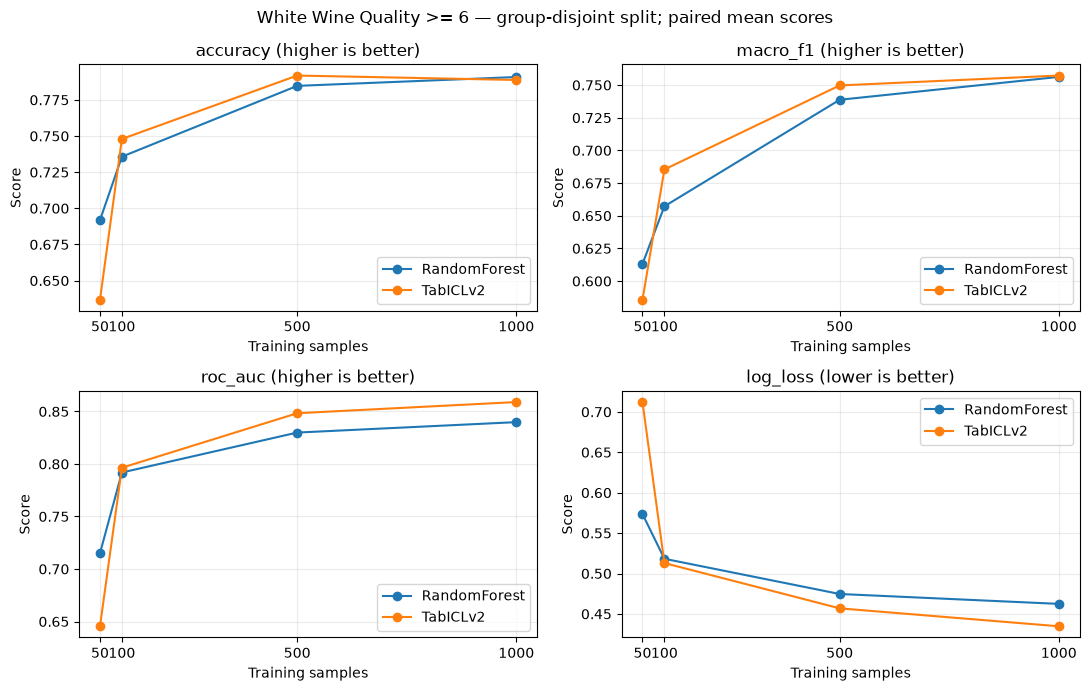

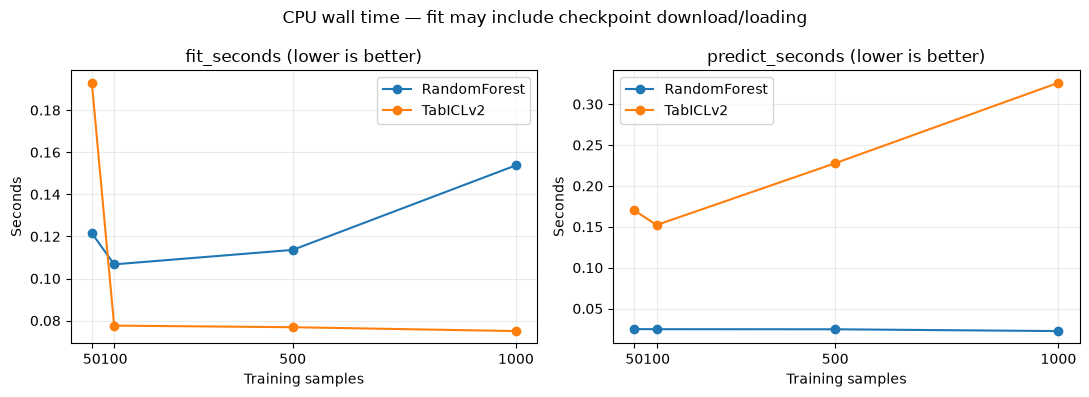

Bảng tổng hợp: /Users/thanhpc02/Documents/CaoHoc/Datamining/BaoCao_GiuaKy/Tabular_4SOTA_CPU/results/wine_quality_white_binary/summary.csv


In [5]:
runs = pd.read_csv(RESULT_FILE)
assert not runs.duplicated(['model', 'seed', 'train_size']).any()
assert runs['dataset'].eq(DATASET_ID).all()
assert runs['dataset_sha256'].eq(DATASET_SHA256).all()
assert runs['quality_threshold'].eq(QUALITY_THRESHOLD).all()
assert runs['split_strategy'].eq(SPLIT_STRATEGY).all()
print('Trạng thái các lượt chạy:')
display(runs.groupby(['model', 'status']).size().rename('n_runs').reset_index())

successful = runs.loc[runs['status'].eq('ok')].copy()
paired = successful.groupby(['seed', 'train_size']).filter(
    lambda group: set(group['model']) == set(MODEL_IDS)
)
for _, group in paired.groupby(['seed', 'train_size']):
    assert group['train_indices_sha256'].nunique() == 1, 'Hai mô hình dùng train khác nhau'
    assert group['test_indices_sha256'].nunique() == 1, 'Hai mô hình dùng test khác nhau'

SCORE_KEYS = ['accuracy', 'macro_f1', 'roc_auc', 'log_loss']
TIME_KEYS = ['fit_seconds', 'predict_seconds']
SUMMARY_FILE = RESULTS / 'summary.csv'
for artifact in ['metrics.png', 'timing.png']:
    (RESULTS / artifact).unlink(missing_ok=True)
summary = paired.groupby(['model', 'train_size'])[SCORE_KEYS + TIME_KEYS].agg(['mean', 'std', 'count'])
summary.columns = ['_'.join(column) for column in summary.columns]
summary = summary.reset_index()
summary.to_csv(SUMMARY_FILE, index=False)
if paired.empty:
    print('Chưa có cặp thành công. Xem error, không suy diễn kết quả.')
    display(runs.loc[runs['status'].ne('ok'), ['model', 'seed', 'train_size', 'error']])
else:
    print('Kết quả trên đúng cùng train/test:')
    display(paired[['model', 'seed', 'train_size', 'test_size', *SCORE_KEYS, *TIME_KEYS]].round(6))
    print('Mean/std/count (std cần ít nhất 2 seed):')
    display(summary.round(6))
    accuracy_table = paired.pivot(index=['seed', 'train_size'], columns='model', values='accuracy')
    accuracy_table['TabICLv2_minus_RF_percentage_points'] = (
        accuracy_table['TabICLv2'] - accuracy_table['RandomForest']
    ) * 100
    display(accuracy_table.round(4))

    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print('Chưa có matplotlib: bảng CSV vẫn được lưu; cài matplotlib để vẽ biểu đồ.')
    else:
        means = paired.groupby(['model', 'train_size'])[SCORE_KEYS + TIME_KEYS].mean()
        for filename, keys, shape in [('metrics.png', SCORE_KEYS, (2, 2)),
                                      ('timing.png', TIME_KEYS, (1, 2))]:
            fig, axes = plt.subplots(*shape, figsize=(11, 7 if len(keys) == 4 else 4))
            for ax, metric in zip(np.asarray(axes).ravel(), keys):
                for model_id in MODEL_IDS:
                    values = means.loc[model_id, metric].sort_index()
                    ax.plot(values.index, values.to_numpy(), marker='o', label=model_id)
                ax.set_title(metric + (' (higher is better)' if metric in SCORE_KEYS[:3]
                                      else ' (lower is better)'))
                ax.set_xlabel('Training samples')
                ax.set_ylabel('Seconds' if metric in TIME_KEYS else 'Score')
                ax.set_xticks(sorted(paired['train_size'].unique()))
                ax.grid(alpha=0.25)
                ax.legend()
            note = ('White Wine Quality >= 6 — group-disjoint split; paired mean scores'
                    if filename == 'metrics.png' else
                    'CPU wall time — fit may include checkpoint download/loading')
            fig.suptitle(note)
            fig.tight_layout()
            fig.savefig(RESULTS / filename, dpi=180, bbox_inches='tight')
            plt.show()
            plt.close(fig)
print('Bảng tổng hợp:', SUMMARY_FILE)